# Forest Fire Prediction - Data Preprocessing

### 1. Import Libraries

In [1]:
# Import standard data science, visualization, and preprocessing libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Ensure figures directory exists
os.makedirs('figures', exist_ok=True)
print("Libraries imported successfully.")

Libraries imported successfully.


### 2. Load the Cleaned Dataset

In [2]:
# Load the cleaned dataset
df = pd.read_csv('Dataset/cleaned_forest_fires.csv')

print("Cleaned Dataset Shape:", df.shape)
df.head()

Cleaned Dataset Shape: (513, 14)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area,area_log1p
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0,0.0


### 3. Define Feature Groups

In [3]:
# Define feature groups
categorical = ['month', 'day']
weather = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']
spatial = ['X', 'Y']

# Non-spatial features (for simpler web app deployment)
features_non_spatial = categorical + weather

# Full feature set including spatial coordinates
features_spatial = spatial + categorical + weather

print("Categorical features:", categorical)
print("Weather features:", weather)
print("Spatial features:", spatial)

Categorical features: ['month', 'day']
Weather features: ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']
Spatial features: ['X', 'Y']


### 4. Train / Test Split (80 / 20)

In [4]:
# Create stratification label to keep zero-fire ratio balanced
strat_label = (df['area'] == 0)

# 80/20 train/test split with random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    df,
    df['area_log1p'],
    test_size=0.20,
    random_state=42,
    stratify=strat_label
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print(f"Train zero-area percentage: {(X_train['area'] == 0).mean() * 100:.2f}%")
print(f"Test zero-area percentage: {(X_test['area'] == 0).mean() * 100:.2f}%")

Training rows: 410
Testing rows: 103
Train zero-area percentage: 47.56%
Test zero-area percentage: 47.57%


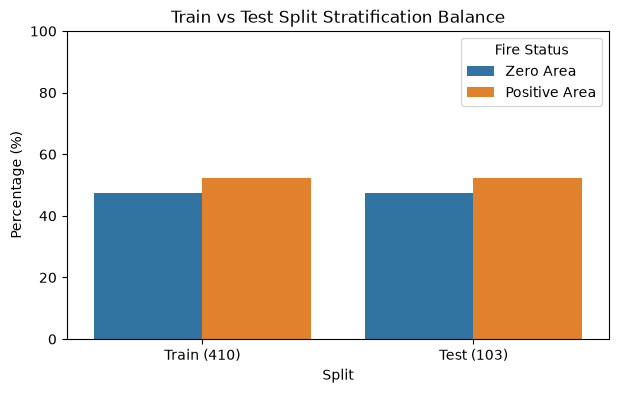

In [5]:
# Side-by-side bar chart of Zero-Area vs Positive-Area percentages in Train vs Test
split_balance_df = pd.DataFrame({
    'Split': [f'Train ({len(X_train)})', f'Train ({len(X_train)})', f'Test ({len(X_test)})', f'Test ({len(X_test)})'],
    'Fire Status': ['Zero Area', 'Positive Area', 'Zero Area', 'Positive Area'],
    'Percentage': [
        (X_train['area'] == 0).mean() * 100,
        (X_train['area'] > 0).mean() * 100,
        (X_test['area'] == 0).mean() * 100,
        (X_test['area'] > 0).mean() * 100
    ]
})

plt.figure(figsize=(7, 4))
sns.barplot(x='Split', y='Percentage', hue='Fire Status', data=split_balance_df)
plt.title('Train vs Test Split Stratification Balance')
plt.ylabel('Percentage (%)')
plt.ylim(0, 100)
plt.savefig('figures/train_test_split_balance.png', bbox_inches='tight')
plt.show()

### 5. Feature Preprocessing

In [6]:
# Calendar lists to ensure all possible months and days are represented
months = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
days = ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']

# Preprocessing transformers
ohe = OneHotEncoder(categories=[months, days], drop='first', sparse_output=False, handle_unknown='ignore')
scaler = StandardScaler()

# Non-spatial preprocessor (25 features)
preprocessor_non_spatial = ColumnTransformer([
    ('cat', ohe, categorical),
    ('num', scaler, weather)
])

# Spatial preprocessor (27 features)
preprocessor_spatial = ColumnTransformer([
    ('cat', ohe, categorical),
    ('num', scaler, spatial + weather)
])

# Fit on training data and transform both train and test sets
X_train_non_spatial = preprocessor_non_spatial.fit_transform(X_train)
X_test_non_spatial = preprocessor_non_spatial.transform(X_test)

X_train_spatial = preprocessor_spatial.fit_transform(X_train)
X_test_spatial = preprocessor_spatial.transform(X_test)

print("Preprocessing complete!")

Preprocessing complete!


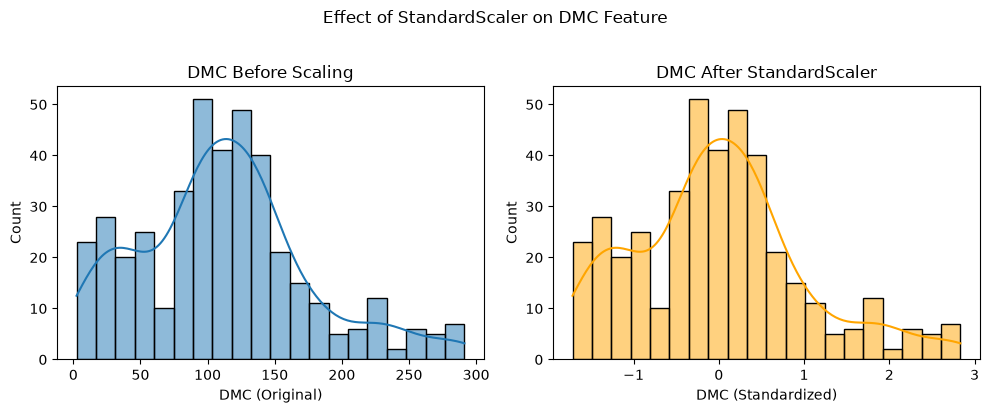

In [7]:
# 2-panel histogram showing DMC distribution before scaling vs after StandardScaler
dmc_idx = list(preprocessor_non_spatial.get_feature_names_out()).index('num__DMC')
dmc_scaled = X_train_non_spatial[:, dmc_idx]

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.histplot(X_train['DMC'], bins=20, kde=True)
plt.title('DMC Before Scaling')
plt.xlabel('DMC (Original)')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.histplot(dmc_scaled, bins=20, kde=True, color='orange')
plt.title('DMC After StandardScaler')
plt.xlabel('DMC (Standardized)')
plt.ylabel('Count')

plt.suptitle('Effect of StandardScaler on DMC Feature', y=1.02)
plt.tight_layout()
plt.savefig('figures/feature_scaling_comparison.png', bbox_inches='tight')
plt.show()

### 6. Verify Processed Arrays

In [8]:
# Check shapes and missing values
print("--- Non-Spatial Feature Set ---")
print("Train shape:", X_train_non_spatial.shape)
print("Test shape:", X_test_non_spatial.shape)
print("Missing values in train:", np.isnan(X_train_non_spatial).sum())
print("Missing values in test:", np.isnan(X_test_non_spatial).sum())

print("\n--- Spatial Feature Set ---")
print("Train shape:", X_train_spatial.shape)
print("Test shape:", X_test_spatial.shape)
print("Missing values in train:", np.isnan(X_train_spatial).sum())
print("Missing values in test:", np.isnan(X_test_spatial).sum())

--- Non-Spatial Feature Set ---
Train shape: (410, 25)
Test shape: (103, 25)
Missing values in train: 0
Missing values in test: 0

--- Spatial Feature Set ---
Train shape: (410, 27)
Test shape: (103, 27)
Missing values in train: 0
Missing values in test: 0
